# 3 Forest fires

## 3.2 Power-law distributions

<div style="background-color:#f0f8ff;border:2px solid #4682b4;padding:10px;">
    
<strong>Note:</strong> This notebook contains the code for sections 3.2 from the book  

**Simulation of Complex Systems**  
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)

You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)

</div>

<a id="fire-size-distribution"></a>
We now study the distribution of sizes $S$ for fires. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sys
from pathlib import Path
sys.path.insert(0, "../03_modules")
import forest_fires as ff

We make sure we discard the initial values of the fires sizes, to allow for equilibration.

In [2]:
N = 64
p = 0.01
f = 0.2

n_steps = 10000
n_discard = 2000

result = ff.simulate(
    n=N, 
    p=p, 
    f=f, 
    steps=n_steps, 
    burn_in=n_discard
)

sizes = result["fire_sizes"]
print(
    f"Recorded {len(sizes)} actual fires; "
    f"largest: {sizes.max() if len(sizes) else 0}"
)

Recorded 770 actual fires; largest: 2891


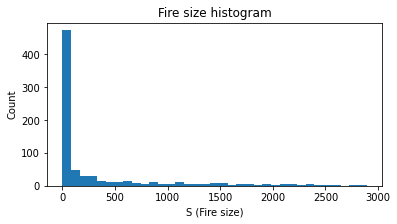

In [3]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(sizes, bins=35)
ax.set(
    xlabel="S (Fire size)", 
    ylabel="Count", 
    title="Fire size histogram"
)
#plt.yscale("log")
plt.show()

Better: Complementary cumulative distribution: 

$$C(n)=P(S\ge n) \qquad \mbox{(Eq. 3.1)}$$ 

This allows to study the rare-events tail by making easier to determine the power-law exponent characterizing the distribution.

<a id="empirical-cCDF"></a>
Let $k$ be the number of recorded fire events.

Let $n \in \{0, ..., k \}$ 

**Empirical cCDF** at $n$ : the number of observed fires whose size is at least $n$, divided by the total number of observed fires. 

To compute it easily, remember to sort the fire sizes first.

In [4]:
sorted_sizes = np.sort(sizes)
k = len(sorted_sizes)
ranks = np.arange(k, 0, -1) / k

print("First five ordered observations:", sorted_sizes[:5])

First five ordered observations: [1 1 1 1 1]


Let's plot the empirical cCDF

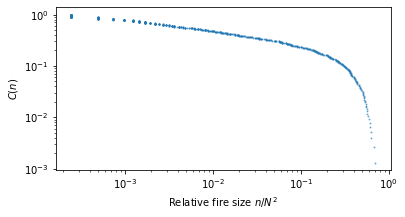

In [5]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.loglog(
    sorted_sizes / N ** 2, 
    ranks, 
    ".", 
    markersize=2, 
    alpha=0.5
)
ax.set(
    xlabel=r"Relative fire size $n/N^2$", 
    ylabel=r"$C(n)$"
)
plt.show()

*Note:* Points with equal size occupy different ranks in the preceding plot. 

At a fixed size $n$, the correct $P(S\ge n)$ includes **all** ties.

`np.unique(..., return_counts=True)` provides an unambiguous cCDF.

In [6]:
values, counts = np.unique(sizes, return_counts=True)

ccdf = np.cumsum(counts[::-1])[::-1] / counts.sum()

Let's plot `ccdf` vs `values / N**2`

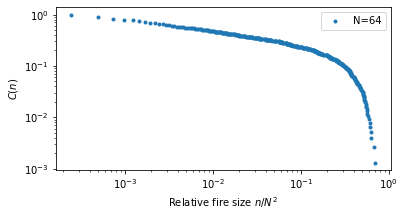

In [7]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.loglog(
    values / N**2, 
    ccdf, 
    ".", 
    label=f"N={N}"
)
ax.set(
    xlabel=r"Relative fire size $n/N^2$", 
    ylabel=r"$C(n)$"
)
ax.legend()
plt.show()


If $p(n) \propto n^{-\alpha}$ with $\alpha>1$, 

then approximating the tail sum $\sum_{m=n}^{\infty}m^{-\alpha}$ by an integral gives:

$C(n)\propto n^{1-\alpha}$

Note that we are in a finite lattice, $n \leq N^2$

<a id="forest-size"></a>
Let's see how the forest size affects the empirical cCDF.

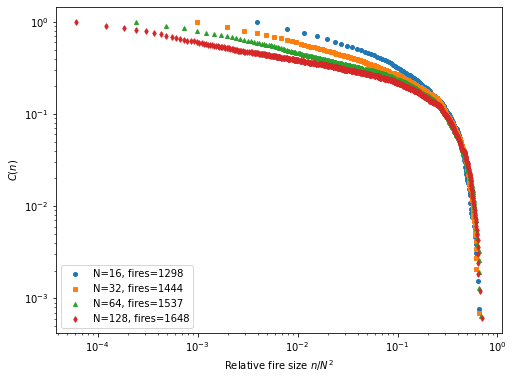

In [8]:
p = 0.01
f = 0.2

n_steps = 20000
n_discard = 2000

markers = ["o", "s", "^", "d"]
forest_sizes = [16, 32, 64, 128]

fig, ax = plt.subplots(figsize=(8, 6))
for N, marker in zip(forest_sizes, markers):
    data = ff.simulate(
        n=N, 
        p=p, 
        f=f, 
        steps=n_steps, 
        burn_in=n_discard
    )
    x, y = ff.empirical_ccdf(data["fire_sizes"])
    ax.loglog(
        x / N**2, 
        y, 
        marker=marker, 
        markersize=4, 
        linestyle="none",
        label=f"N={N}, fires={len(data['fire_sizes'])}"
    )
ax.set(
    xlabel=r"Relative fire size $n/N^2$", 
    ylabel=r"$C(n)$"
)
ax.legend()
plt.show()

<a id="random-forest"></a>
**Exercise 3.5:** comparison against a random forest.

Is the fire size distribution different?

For every actual fire, we compare against a **new**, randomly occupied forest with the **same number of trees immediately before the fire**. 

The comparison selects an occupied tree as its ignition site; thus both samples are conditional on a fire occurring. 

This isolates differences in spatial structure rather than differences in forest density.

In [9]:
N = 64
p = 0.01
f = 0.2

n_steps = 20000
n_discard = 2000

matched = ff.simulate(
    n=N, 
    p=p, 
    f=f, 
    steps=n_steps, 
    burn_in=n_discard, 
    compare_random=True
)

grown = matched["fire_sizes"]
random_fires = matched["random_fire_sizes"]

print("Paired events:", len(grown), len(random_fires))

Paired events: 1566 1566


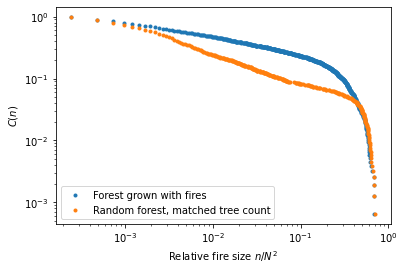

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
for label, data in [
    ("Forest grown with fires", grown), 
    ("Random forest, matched tree count", random_fires)
]:
    x, y = ff.empirical_ccdf(data)
    ax.loglog(
        x / N**2, 
        y, 
        ".", 
        label=label
    )
    
ax.set(
    xlabel=r"Relative fire size $n/N^2$", 
    ylabel=r"$C(n)$"
)

ax.legend()
plt.show()

Can you interpret the plot?

<a id="questions"></a>
## Questions

Here you find the questions:

- [Q5: Fire size distribution](#q5)
- [Q6: Empirical cCDF](#q6)
- [Q7: Effect of forest size](#q7)
- [Q8: Comparison with randomly grown forest](#q8)

<a id="q5"></a>
**Q5: Fire size distribution.**

Refer to [fire size distribution](#fire-size-distribution) and the [module](../03_modules/forest_fires.py)

[Go back to questions](#questions)

a. Explain what is the effect of setting `n_discard = 0` in 
```python
result = ff.simulate(
    n=N, 
    p=p, 
    f=f, 
    steps=n_steps, 
    burn_in=n_discard
)
```
Examine the function body and explain the implications.


b. Consider the function `simulate` in the module `forest_fires.py`. Modify it so that the *default value* of the optional parameter `steps` is `10000`. 


<a id="q6"></a>
**Q6: Empirical cCDF.**

Refer to [empirical cCDF](#empirical-CCDF) and the [module](../03_modules/forest_fires.py)

[Go back to questions](#questions)

a. Consider the lines:
```python
sorted_sizes = np.sort(sizes)
k = len(sorted_sizes)
ranks = np.arange(k, 0, -1) / k
```
and the lines:
```python
ax.loglog(
    sorted_sizes / N ** 2, 
    ranks, 
    ".", 
    markersize=2, 
    alpha=0.5
)
```
where `ranks` are plotted versus `sorted_sizes / N ** 2`.

Can you explain the decision to plot using `loglog`? 

b. Consider the lines: 
```python
values, counts = np.unique(sizes, return_counts=True)
ccdf = np.cumsum(counts[::-1])[::-1] / counts.sum()
```
and the lines for the plot:
```python
ax.loglog(
    values / N**2, 
    ccdf, 
    ".", 
    label=f"N={N}"
)
```
What is the main difference between this plot and the one of `ranks` versus `sorted_sizes / N ** 2`? Explain.


c. Explain the syntax: `a = np.cumsum(counts[::-1])[::-1]`.


d. Assume `counts = np.array([10, 5, 1])` and `a = np.cumsum(counts[::-1])[::-1]`. 
What is the output of `print(a)` ?

<a id="q7"></a>
**Q7: Effect of forest size.**

Refer to [effect of forest size](#forest-size) and the [module](../03_modules/forest_fires.py)

[Go back to questions](#questions)

Analyze the plot of the cCDF vs the relative fire size for different forest sizes. There are four cases: `N = 16`, `N = 32`, `N = 64`, `N = 128`, 

a. Why for `N = 16` the smallest value of the relative fire size is between `10^(-3)` and `10^(-2)`, while the one for `N = 128` is between `10^(-5)` and `10^(-4)`? 


b. All four cCDFs have a similar linear decreasing trend at the beginning (i.e., for relative fire sizes smaller than `10^(-1)`). What indicates this linear trend in the loglog plot?


c. All four cCDFs have a similar abrupt drop towards the end (i.e., for relative fire sizes larger than `10^(-1)`). 
Explain why this trend is a finite-size affect. 


d. Attempt to draw a plausible plot of the cCDF vs the relative fire size for `N = 256`. Draw it on top of the plot with the four cases. Justify your choices for the dependence.

<a id="q8"></a>
**Q8: Comparison with randomly grown forest.**

Refer to [randomly grown forest](#random-forest) and the [module](../03_modules/forest_fires.py)

[Go back to questions](#questions)

a. Consider the line: 
```python
print("Paired events:", len(grown), len(random_fires))
```
The output shown in the notebook consists of two equal numbers. Why is it always the case? Explain.

b. Observe the graph with the comparison between the randomly grown forest and the fire-grown forest.
Are the two cCDF similar? What is different? Explain.

